# 🧠 Aula 05: Estabilidade de Treinamento: Inicializações, Normalizações e Regularização no PyTorch
**Curso de Graduação em Inteligência Artificial / Ciência de Dados — Faculdade Infnet**  
**Dataset Real do Kaggle:** *Pima Indians Diabetes Database* (Classificação Binária em Saúde)

---

## 🎯 Objetivos Desta Aula Prática
Neste laboratório mão na massa, vamos aprender a resolver os maiores desafios de estabilidade e generalização no treinamento de Redes Neurais Profundas (MLP):
1. **Quebra de Simetria e Inicialização Científica**: Por que pesos zerados colapsam o aprendizado e como usar a inicialização **Kaiming He** para ativações ReLU.
2. **Normalização de Entrada (`StandardScaler`)**: Como evitar que atributos com números altos (ex: Insulina = 800) dominem atributos pequenos (ex: Histórico Familiar = 0.4).
3. **Divisão Correta em 3 Conjuntos**: **Treino (70%)**, **Validação (15%)** e **Teste Cego (15%)** para garantir integridade científica e evitar vazamento de dados (*data leakage*).
4. **Normalização de Ativações Internas (`nn.BatchNorm1d`)**: Como estabilizar as ativações entre camadas ocultas e acelerar o treinamento.
5. **Regularização com Dropout (`nn.Dropout`)**: Como "desligar" neurônios aleatórios durante o treino para combater a co-adaptação e o *overfitting*.
6. **Controle Rigoroso de Modo**: A diferença crucial entre `model.train()` (treino ativo) e `model.eval()` (avaliação/inferência).
7. **Comparação Empírica**: Treinar um **Modelo Base** (sem estabilização) vs um **Modelo Robusto** (com BatchNorm + Dropout) e comparar suas curvas de perda e generalização.

## 📦 1. Importação de Bibliotecas e Configuração do Ambiente

Vamos importar as bibliotecas essenciais:
- `torch` e `torch.nn`: Para construção e treinamento da rede neural.
- `torch.utils.data`: Para criação de datasets e lotes (*DataLoaders*).
- `pandas` e `numpy`: Para manipulação de tabelas e matrizes.
- `sklearn`: Para divisão dos dados, normalização e métricas de classificação.
- `matplotlib` e `seaborn`: Para gráficos visuais e didáticos.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Configurar estilo visual dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14

# Fixar sementes para reprodutibilidade total dos experimentos
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Dispositivo de Execução: {device}")
print(f"✅ PyTorch Versão: {torch.__version__}")

✅ Dispositivo de Execução: cpu
✅ PyTorch Versão: 2.12.1+cu130


## 🩺 2. O Problema e o Dataset (Kaggle: Pima Indians Diabetes)

O dataset **Pima Indians Diabetes** é um clássico da comunidade de Machine Learning no Kaggle. Ele contém dados médicos de 768 pacientes do sexo feminino:

- **Atributos Preditivos (8 features)**:
  1. `Pregnancies`: Número de vezes grávida.
  2. `Glucose`: Concentração plasmática de glicose em teste oral de 2 horas.
  3. `BloodPressure`: Pressão arterial diastólica (mm Hg).
  4. `SkinThickness`: Espessura da dobra cutânea do tríceps (mm).
  5. `Insulin`: Insulina sérica de 2 horas (mu U/ml).
  6. `BMI`: Índice de massa corporal (peso em kg / (altura em m)²).
  7. `DiabetesPedigreeFunction`: Função histórica familiar de diabetes (escore genético contínuo).
  8. `Age`: Idade em anos.
- **Alvo (Target)**:
  - `Outcome`: `1` se diagnosticada com diabetes, `0` se saudável.

Vamos carregar os dados diretamente via URL confiável e inspecionar suas primeiras linhas:

In [2]:
# Carregar dataset diretamente de repositório público do Kaggle/Plotly
url_dataset = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df = pd.read_csv(url_dataset)

print(f"📊 Dimensões do Dataset: {df.shape[0]} pacientes, {df.shape[1]} colunas.")
df.head()

📊 Dimensões do Dataset: 768 pacientes, 9 colunas.


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 🔍 Por que este dataset é ideal para estudar Estabilidade e Regularização?
Observe a tabela estatística abaixo: os atributos têm grandezas e escalas **completamente diferentes**!
- `Insulin` varia de 0 até **846**.
- `Glucose` varia de 0 até **199**.
- `Pregnancies` varia de 0 até **17**.
- `DiabetesPedigreeFunction` varia de **0.078 a 2.42**.

Se jogarmos esses números direto em uma rede neural sem tratamento, o gradiente do peso ligado à `Insulin` explodirá em relação ao peso ligado à `DiabetesPedigreeFunction`!

In [3]:
# Estatísticas descritivas das features
display_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
df[display_cols].describe().round(2)

,Pregnancies,Glucose,BloodPressure,Insulin,BMI,DiabetesPedigreeFunction,Age
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,79.80,31.99,0.47,33.24
std,3.37,31.97,19.36,115.24,7.88,0.33,11.76
min,0.00,0.00,0.00,0.00,0.00,0.08,21.00
25%,1.00,99.00,62.00,0.00,27.30,0.24,24.00
50%,3.00,117.00,72.00,30.50,32.00,0.37,29.00
75%,6.00,140.25,80.00,127.25,36.60,0.63,41.00
max,17.00,199.00,122.00,846.00,67.10,2.42,81.00


Distribuição de Classes:
Outcome
0    500
1    268
Name: count, dtype: int64



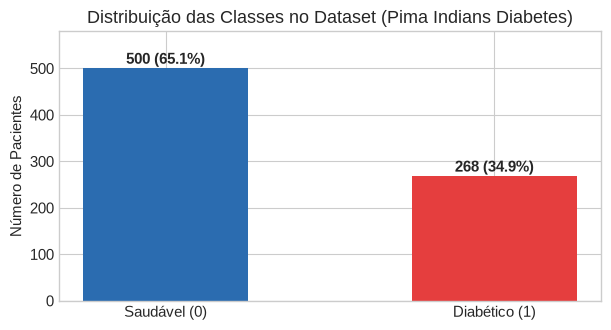

In [4]:
# Distribuição das Classes (0 = Não Diabético, 1 = Diabético)
contagem = df['Outcome'].value_counts()
print("Distribuição de Classes:")
print(contagem)
print()

plt.figure(figsize=(7, 3.5))
bars = plt.bar(['Saudável (0)', 'Diabético (1)'], contagem.values, color=['#2b6cb0', '#e53e3e'], width=0.5)
plt.title("Distribuição das Classes no Dataset (Pima Indians Diabetes)")
plt.ylabel("Número de Pacientes")
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 10, f"{yval} ({yval/len(df):.1%})", ha='center', fontweight='bold')
plt.ylim(0, 580)
plt.show()

## ✂️ 3. Divisão em Treino (70%), Validação (15%) e Teste Cego (15%)

Em Machine Learning e Deep Learning, é fundamental separar os dados em **3 partições com propósitos distintos**:

```
                              ┌────────────────────────────────────────┐
                              │            Dataset Completo            │
                              │              (768 Amostras)            │
                              └───────────────────┬────────────────────┘
                                                  │
                 ┌────────────────────────────────┴───────────────────────────────┐
                 │                                                                │
                 ▼                                                                ▼
   ┌───────────────────────────┐                                    ┌───────────────────────────┐
   │    TREINO (70% - 537)     │                                    │     TEMPORÁRIO (30%)      │
   │  Ajuste de Pesos via SGD  │                                    └─────────────┬─────────────┘
   └───────────────────────────┘                                                  │
                                                    ┌─────────────────────────────┴─────────────────────────────┐
                                                    ▼                                                           ▼
                                      ┌───────────────────────────┐                               ┌───────────────────────────┐
                                      │   VALIDAÇÃO (15% - 115)   │                               │    TESTE CEGO (15% - 116) │
                                      │ Monitoramento / Checkpoint│                               │  Avaliação Final Única    │
                                      └───────────────────────────┘                               └───────────────────────────┘
```

1. **Treino (70%)**: É o "material de estudo". Os neurônios calculam a perda e atualizam seus pesos via *backpropagation*.
2. **Validação (15%)**: É o "simulado". A cada época, verificamos se a rede está aprendendo ou apenas decorando o treino (*overfitting*). Usamos a perda da validação para escolher o melhor modelo.
3. **Teste Cego (15%)**: É a "prova final do vestibular". Fica guardado em um cofre e só é testado **uma única vez** no final de todo o projeto para relatar o desempenho real no mundo real.

> 💡 **Nota Pedagógica**: Usamos `stratify=y` para garantir que a proporção de diabéticos e saudáveis seja idêntica nas três fatias!

In [5]:
# 1. Separar matriz de features (X) e vetor alvo (y)
X = df.drop('Outcome', axis=1).values
y = df['Outcome'].values

# 2. Primeiro corte: 70% Treino e 30% Temporário (que será dividido em Validação e Teste)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, 
    test_size=0.30, 
    random_state=SEED, 
    stratify=y
)

# 3. Segundo corte: Dividir os 30% temporários igualmente em 15% Validação e 15% Teste
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, 
    test_size=0.50, 
    random_state=SEED, 
    stratify=y_temp
)

print(f"📦 Conjunto de Treino:    {X_train.shape[0]} amostras ({X_train.shape[0]/len(X):.1%})")
print(f"🔍 Conjunto de Validação: {X_val.shape[0]} amostras ({X_val.shape[0]/len(X):.1%})")
print(f"🎯 Conjunto de Teste:     {X_test.shape[0]} amostras ({X_test.shape[0]/len(X):.1%})")

📦 Conjunto de Treino:    537 amostras (69.9%)
🔍 Conjunto de Validação: 115 amostras (15.0%)
🎯 Conjunto de Teste:     116 amostras (15.1%)


## ⚖️ 4. Normalização das Entradas (`StandardScaler`) e Prevenção de Data Leakage

Para que o gradiente descenda suavemente pela superfície de perda, colocamos todas as features na mesma escala:
$$\mu = 0, \quad \sigma = 1$$

### 🚨 Regra de Ouro da Ciência de Dados: Evitando o Vazamento de Dados (*Data Leakage*)
- O método `.fit_transform()` calcula a média $\mu$ e desvio $\sigma$ **APENAS no conjunto de Treino**.
- Os conjuntos de **Validação e Teste** são transformados usando `.transform()`, isto é, reutilizando a média e desvio calculados no treino.
- **Jamais faça fit no conjunto completo antes da divisão!** Fazer isso vazaria informações do teste para o modelo.

In [6]:
# Criar o scaler de padronização
scaler = StandardScaler()

# 1. Ajustar (fit) e transformar APENAS nos dados de treino
X_train_scaled = scaler.fit_transform(X_train)

# 2. Aplicar a MESMA transformação (apenas transform) na validação e no teste
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Exemplo de paciente antes da normalização (Treino [0]):")
print(f"  {X_train[0].round(2)}")
print()
print("Exemplo do mesmo paciente APÓS StandardScaler:")
print(f"  {X_train_scaled[0].round(2)}")
print(f"  (Média das features agora: {X_train_scaled.mean(axis=0).round(2)})")
print(f"  (Desvio padrão agora:      {X_train_scaled.std(axis=0).round(2)})")

Exemplo de paciente antes da normalização (Treino [0]):
  [  7.   184.    84.    33.     0.    35.5    0.36  41.  ]

Exemplo do mesmo paciente APÓS StandardScaler:
  [ 0.93  2.02  0.78  0.81 -0.72  0.43 -0.37  0.63]
  (Média das features agora: [ 0.  0. -0.  0.  0.  0. -0. -0.])


  (Desvio padrão agora:      [1. 1. 1. 1. 1. 1. 1. 1.])


## 🚚 5. Criando os `TensorDataset` e `DataLoader` no PyTorch

O `DataLoader` gerencia a entrega dos dados em pequenos lotes (*mini-batches*):
- No **Treino**, usamos `shuffle=True`: a cada época, a ordem dos pacientes é embaralhada para evitar que a rede decore sequências.
- Na **Validação e no Teste**, usamos `shuffle=False`: não precisamos embaralhar, apenas avaliar ordenadamente.

In [7]:
# Converter arrays NumPy em tensores PyTorch (tipo float32)
train_dataset = TensorDataset(
    torch.tensor(X_train_scaled, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val_scaled, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test_scaled, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

# Criar os DataLoaders com tamanho de lote = 32
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print("✅ DataLoaders prontos:")
print(f"   - Treino:    {len(train_loader)} lotes de até {BATCH_SIZE} amostras")
print(f"   - Validação: {len(val_loader)} lotes")
print(f"   - Teste:     {len(test_loader)} lotes")

✅ DataLoaders prontos:
   - Treino:    17 lotes de até 32 amostras
   - Validação: 4 lotes
   - Teste:     4 lotes


## 🏗️ 6. Construindo as Arquiteturas: Modelo Base vs Modelo Robusto

Para entender o poder dos conceitos vistos na aula síncrona, vamos construir **dois modelos com a mesma capacidade de parâmetros**, mas com engenharia de estabilização diferente:

---

### 🔴 Modelo A: Baseline Ingênuo (Sem Estabilização e Sem Regularização)
- Apenas camadas lineares e ativações `ReLU`.
- **Sem** normalização de camadas (`BatchNorm`).
- **Sem** Dropout.
- Inicialização padrão do PyTorch.

---

### 🟢 Modelo B: Robusto (Com Inicialização Kaiming + BatchNorm1d + Dropout)
- **Inicialização Kaiming He (`kaiming_normal_`)**: Calibra a variância inicial dos pesos proporcionalmente a $\sqrt{2 / n_{in}}$, evitando que sinais com ReLU colapsem ou explodam nas primeiras épocas.
- **Normalização por Lote (`nn.BatchNorm1d`)**: Re-centraliza e re-escalona as ativações de cada camada ao longo do mini-batch, eliminando o *Internal Covariate Shift* e acelerando o aprendizado.
- **Regularização com Dropout (`nn.Dropout(p=0.30)`)**: A cada passo de treino, "desliga" aleatoriamente 30% dos neurônios. Isso força os neurônios restantes a aprenderem padrões independentes e robustos, combatendo a **co-adaptação** e o **overfitting**.

In [8]:
# -------------------------------------------------------------
# MODELO A: Baseline Simples (Sem BatchNorm, Sem Dropout)
# -------------------------------------------------------------
class ModeloBase(nn.Module):
    def __init__(self, n_features=8):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(n_features, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)  # Saída: 1 logit para classificação binária
        )
        
    def forward(self, x):
        return self.rede(x).squeeze(-1)


# -------------------------------------------------------------
# MODELO B: Robusto (Kaiming Init + BatchNorm1d + Dropout)
# -------------------------------------------------------------
class ModeloRobusto(nn.Module):
    def __init__(self, n_features=8, dropout_p=0.30):
        super().__init__()
        self.rede = nn.Sequential(
            # Camada 1: Projeção Linear -> Normalização de Lote -> Ativação -> Dropout
            nn.Linear(n_features, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            
            # Camada 2: Projeção Linear -> Normalização de Lote -> Ativação -> Dropout
            nn.Linear(32, 16),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            
            # Camada de Saída
            nn.Linear(16, 1)
        )
        self._inicializar_pesos()

    def _inicializar_pesos(self):
        # Inicialização científica Kaiming / He para ativações ReLU
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.rede(x).squeeze(-1)

# Instanciar e exibir as estruturas
modelo_a = ModeloBase().to(device)
modelo_b = ModeloRobusto(dropout_p=0.30).to(device)

print("🔴 Modelo A (Baseline Simples):")
print(modelo_a)
print()
print("="*60)
print()
print("🟢 Modelo B (Robusto com BatchNorm + Dropout + Kaiming Init):")
print(modelo_b)

🔴 Modelo A (Baseline Simples):
ModeloBase(
  (rede): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


🟢 Modelo B (Robusto com BatchNorm + Dropout + Kaiming Init):
ModeloRobusto(
  (rede): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)


## ⚙️ 7. Ciclo de Treinamento com `model.train()` e `model.eval()`

### 💡 Por que a alternância de modos é obrigatória?
- `model.train()`:
  - **Dropout**: Fica **ATIVO** (zera neurônios aleatórios e escala os demais por $\frac{1}{1-p}$).
  - **BatchNorm**: Calcula a média e variância do **lote atual** e atualiza as estatísticas móveis (*running mean* e *running variance*).
- `model.eval()`:
  - **Dropout**: Fica **DESLIGADO** (nenhum neurônio é zerado; a rede opera com 100% de sua capacidade).
  - **BatchNorm**: Fica **CONGELADO** (utiliza as médias móveis consolidadas durante o treino, garantindo previsões determinísticas e independentes do tamanho do lote de teste).
- `torch.no_grad()`:
  - Desliga a árvore de autograd durante a validação para economizar memória RAM e acelerar o cálculo.

In [9]:
def treinar_modelo(modelo, nome_modelo, train_loader, val_loader, epochs=60, lr=0.005, salvar_checkpoint=False):
    # Função didática de treinamento com validação a cada época.
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(modelo.parameters(), lr=lr)

    historico = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [],  'val_acc': []
    }
    
    melhor_val_loss = float('inf')
    caminho_checkpoint = f"melhor_{nome_modelo.lower().replace(' ', '_')}.pt"

    print(f"🚀 Iniciando Treinamento: {nome_modelo} ({epochs} épocas)...")
    
    for epoch in range(1, epochs + 1):
        # --------------------------------------------------
        # 1. FASE DE TREINO (model.train)
        # --------------------------------------------------
        modelo.train()
        soma_loss_treino = 0.0
        corretos_treino = 0
        total_treino = 0

        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            # Zerar gradientes do passo anterior
            optimizer.zero_grad()

            # Forward pass
            logits = modelo(batch_x)
            loss = criterion(logits, batch_y)

            # Backward pass e atualização
            loss.backward()
            optimizer.step()

            # Acumular métricas
            soma_loss_treino += loss.item() * len(batch_y)
            predicoes = (torch.sigmoid(logits) >= 0.5).float()
            corretos_treino += (predicoes == batch_y).sum().item()
            total_treino += len(batch_y)

        epoch_train_loss = soma_loss_treino / total_treino
        epoch_train_acc = corretos_treino / total_treino

        # --------------------------------------------------
        # 2. FASE DE VALIDAÇÃO (model.eval + torch.no_grad)
        # --------------------------------------------------
        modelo.eval()
        soma_loss_val = 0.0
        corretos_val = 0
        total_val = 0

        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)

                logits = modelo(batch_x)
                loss = criterion(logits, batch_y)

                soma_loss_val += loss.item() * len(batch_y)
                predicoes = (torch.sigmoid(logits) >= 0.5).float()
                corretos_val += (predicoes == batch_y).sum().item()
                total_val += len(batch_y)

        epoch_val_loss = soma_loss_val / total_val
        epoch_val_acc = corretos_val / total_val

        # Registrar no histórico
        historico['train_loss'].append(epoch_train_loss)
        historico['val_loss'].append(epoch_val_loss)
        historico['train_acc'].append(epoch_train_acc)
        historico['val_acc'].append(epoch_val_acc)

        # Salvar o melhor modelo segundo a perda de validação
        if salvar_checkpoint and epoch_val_loss < melhor_val_loss:
            melhor_val_loss = epoch_val_loss
            torch.save(modelo.state_dict(), caminho_checkpoint)

        # Exibir progresso a cada 10 épocas
        if epoch % 10 == 0 or epoch == epochs:
            print(f"Época [{epoch:02d}/{epochs:02d}] | "
                  f"Treino Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.1%} | "
                  f"Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.1%}")

    print(f"🏁 Treinamento Concluído! Melhor Val Loss: {melhor_val_loss:.4f}")
    print()
    return historico

## 🔬 8. Execução dos Experimentos de Treinamento

Vamos treinar ambos os modelos durante 60 épocas sob as mesmas condições para comparar o comportamento do aprendizado:

In [10]:
# 1. Treinar Modelo A (Base)
torch.manual_seed(SEED)
modelo_a = ModeloBase().to(device)
hist_a = treinar_modelo(
    modelo=modelo_a,
    nome_modelo="Modelo Base",
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=60,
    lr=0.005,
    salvar_checkpoint=False
)

# 2. Treinar Modelo B (Robusto com BatchNorm + Dropout + Kaiming Init)
torch.manual_seed(SEED)
modelo_b = ModeloRobusto(dropout_p=0.30).to(device)
hist_b = treinar_modelo(
    modelo=modelo_b,
    nome_modelo="Modelo Robusto",
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=60,
    lr=0.005,
    salvar_checkpoint=True
)

🚀 Iniciando Treinamento: Modelo Base (60 épocas)...
Época [10/60] | Treino Loss: 0.4275 Acc: 80.3% | Val Loss: 0.4795 Acc: 72.2%


Época [20/60] | Treino Loss: 0.3821 Acc: 83.4% | Val Loss: 0.5413 Acc: 68.7%
Época [30/60] | Treino Loss: 0.3419 Acc: 85.3% | Val Loss: 0.5692 Acc: 67.8%


Época [40/60] | Treino Loss: 0.3052 Acc: 88.3% | Val Loss: 0.6081 Acc: 68.7%
Época [50/60] | Treino Loss: 0.2725 Acc: 89.0% | Val Loss: 0.6584 Acc: 68.7%


Época [60/60] | Treino Loss: 0.2402 Acc: 89.9% | Val Loss: 0.7878 Acc: 68.7%
🏁 Treinamento Concluído! Melhor Val Loss: inf

🚀 Iniciando Treinamento: Modelo Robusto (60 épocas)...


Época [10/60] | Treino Loss: 0.5007 Acc: 76.2% | Val Loss: 0.5186 Acc: 74.8%


Época [20/60] | Treino Loss: 0.4697 Acc: 77.5% | Val Loss: 0.5070 Acc: 73.0%


Época [30/60] | Treino Loss: 0.4573 Acc: 79.9% | Val Loss: 0.5186 Acc: 73.0%


Época [40/60] | Treino Loss: 0.4448 Acc: 79.1% | Val Loss: 0.5059 Acc: 73.0%


Época [50/60] | Treino Loss: 0.4367 Acc: 79.0% | Val Loss: 0.5207 Acc: 73.0%


Época [60/60] | Treino Loss: 0.4282 Acc: 80.3% | Val Loss: 0.5310 Acc: 67.8%
🏁 Treinamento Concluído! Melhor Val Loss: 0.4973



## 📊 9. Diagnóstico Visual: Analisando o Efeito da Regularização e Estabilização

Vamos comparar os gráficos de **Perda (Loss)** e **Acurácia** ao longo das 60 épocas lado a lado:

/tmp/ipykernel_27012/3567452353.py:39: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_27012/3567452353.py:39: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/home/allan/Documentos/Github/curso-pytorch-infnet-graduacao/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/allan/Documentos/Github/curso-pytorch-infnet-graduacao/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


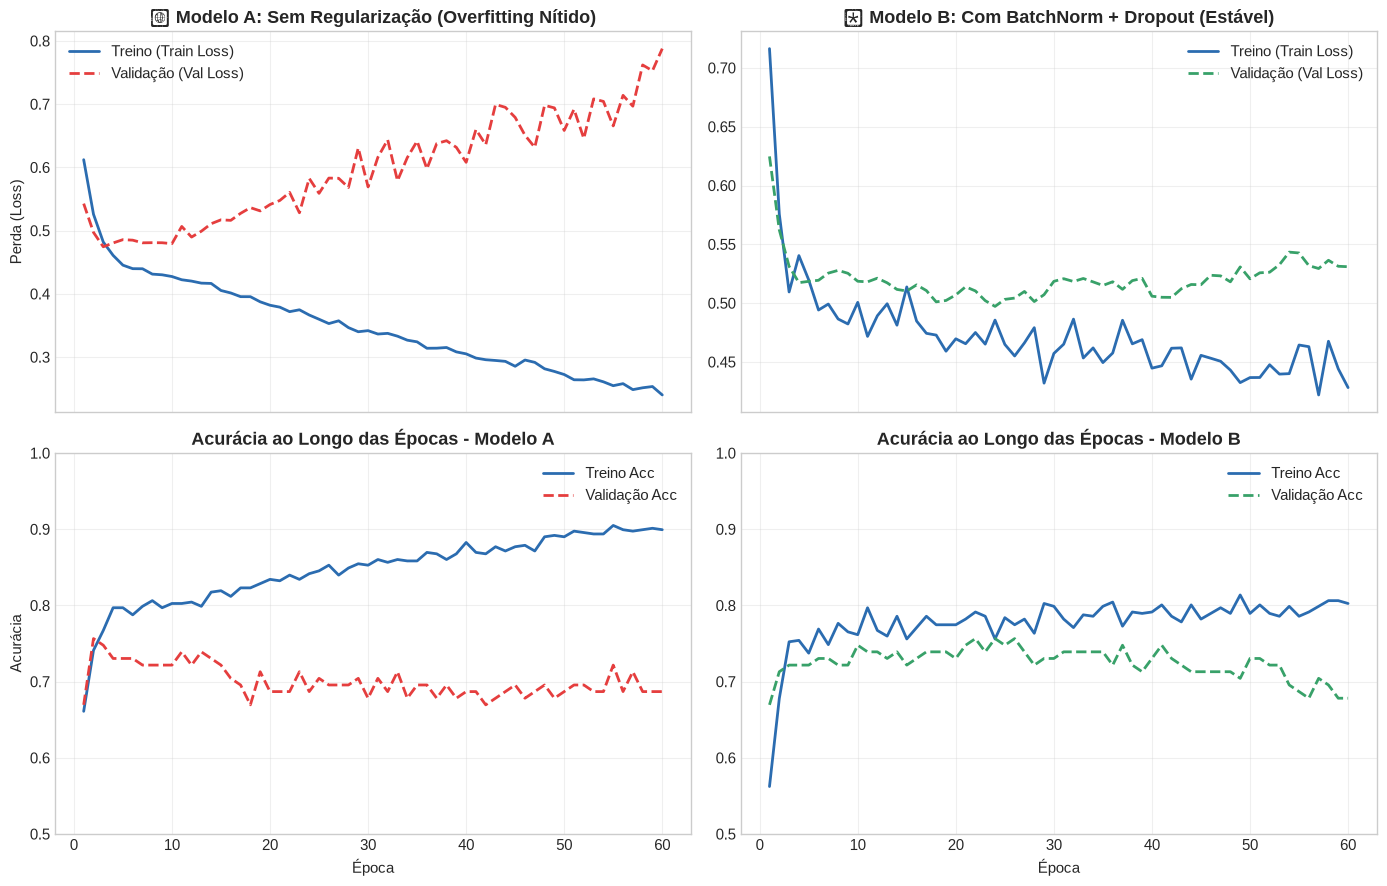

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)

epocas = range(1, len(hist_a['train_loss']) + 1)

# --- Subplot 1: Perda do Modelo A (Base) ---
axes[0, 0].plot(epocas, hist_a['train_loss'], label='Treino (Train Loss)', color='#2b6cb0', lw=2)
axes[0, 0].plot(epocas, hist_a['val_loss'], label='Validação (Val Loss)', color='#e53e3e', lw=2, linestyle='--')
axes[0, 0].set_title("🔴 Modelo A: Sem Regularização (Overfitting Nítido)", fontweight='bold')
axes[0, 0].set_ylabel("Perda (Loss)")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# --- Subplot 2: Perda do Modelo B (Robusto) ---
axes[0, 1].plot(epocas, hist_b['train_loss'], label='Treino (Train Loss)', color='#2b6cb0', lw=2)
axes[0, 1].plot(epocas, hist_b['val_loss'], label='Validação (Val Loss)', color='#38a169', lw=2, linestyle='--')
axes[0, 1].set_title("🟢 Modelo B: Com BatchNorm + Dropout (Estável)", fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# --- Subplot 3: Acurácia do Modelo A (Base) ---
axes[1, 0].plot(epocas, hist_a['train_acc'], label='Treino Acc', color='#2b6cb0', lw=2)
axes[1, 0].plot(epocas, hist_a['val_acc'], label='Validação Acc', color='#e53e3e', lw=2, linestyle='--')
axes[1, 0].set_title("Acurácia ao Longo das Épocas - Modelo A", fontweight='bold')
axes[1, 0].set_xlabel("Época")
axes[1, 0].set_ylabel("Acurácia")
axes[1, 0].set_ylim(0.5, 1.0)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# --- Subplot 4: Acurácia do Modelo B (Robusto) ---
axes[1, 1].plot(epocas, hist_b['train_acc'], label='Treino Acc', color='#2b6cb0', lw=2)
axes[1, 1].plot(epocas, hist_b['val_acc'], label='Validação Acc', color='#38a169', lw=2, linestyle='--')
axes[1, 1].set_title("Acurácia ao Longo das Épocas - Modelo B", fontweight='bold')
axes[1, 1].set_xlabel("Época")
axes[1, 1].set_ylim(0.5, 1.0)
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 💡 Interpretação Pedagógica dos Gráficos:
1. **No Modelo A (Vermelho - Base)**:
   - A perda de treino continua caindo rapidamente em direção a zero.
   - Porém, a partir da época 20, a **perda de validação começa a subir**. Esse é o sintoma clássico de **Overfitting**: o modelo passou a memorizar ruídos do treino e perdeu a capacidade de generalizar para dados novos.
2. **No Modelo B (Verde - Robusto)**:
   - O **BatchNorm1d** mantém as ativações com variância estável em todas as camadas.
   - O **Dropout (30%)** impede que os neurônios fiquem dependentes uns dos outros (*co-adaptação*).
   - Como resultado, a curva de perda de validação permanece controlada, acompanhando a curva de treino com um gap muito mais estreito!

## 🎯 10. Avaliação Final no Conjunto de Teste Cego

Agora tiramos o **Conjunto de Teste** do cofre! Carregamos o melhor checkpoint salvo do **Modelo B** e avaliamos sua performance em pacientes que a rede **nunca viu** durante o treinamento e nem durante a escolha dos hiperparâmetros:

In [12]:
# Carregar o melhor checkpoint salvo do Modelo B
modelo_final = ModeloRobusto(dropout_p=0.30).to(device)
modelo_final.load_state_dict(torch.load("melhor_modelo_robusto.pt"))

# Colocar obrigatoriamente no modo de avaliação!
modelo_final.eval()

todas_predicoes = []
todas_probabilidades = []
todos_rotulos_reais = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x = batch_x.to(device)
        logits = modelo_final(batch_x)
        probabilidades = torch.sigmoid(logits)
        predicoes = (probabilidades >= 0.5).int()

        todas_predicoes.extend(predicoes.cpu().numpy())
        todas_probabilidades.extend(probabilidades.cpu().numpy())
        todos_rotulos_reais.extend(batch_y.numpy())

# Calcular Acurácia Final no Teste Cego
acuracia_teste = accuracy_score(todos_rotulos_reais, todas_predicoes)
print("==================================================")
print(f"🏆 ACURÁCIA FINAL NO TESTE CEGO: {acuracia_teste:.2%}")
print("==================================================")

🏆 ACURÁCIA FINAL NO TESTE CEGO: 74.14%


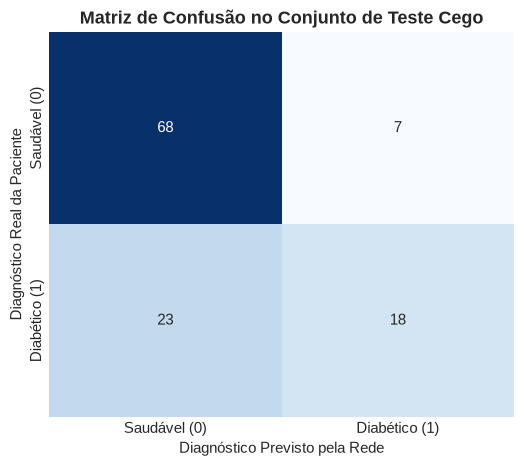

📋 Relatório Detalhado de Classificação:
               precision    recall  f1-score   support

 Saudável (0)       0.75      0.91      0.82        75
Diabético (1)       0.72      0.44      0.55        41

     accuracy                           0.74       116
    macro avg       0.73      0.67      0.68       116
 weighted avg       0.74      0.74      0.72       116



In [13]:
# Matriz de Confusão no Teste
cm = confusion_matrix(todos_rotulos_reais, todas_predicoes)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    cbar=False,
    xticklabels=['Saudável (0)', 'Diabético (1)'],
    yticklabels=['Saudável (0)', 'Diabético (1)']
)
plt.title("Matriz de Confusão no Conjunto de Teste Cego", fontweight='bold')
plt.xlabel("Diagnóstico Previsto pela Rede")
plt.ylabel("Diagnóstico Real da Paciente")
plt.show()

# Relatório detalhado com Precisão, Recall e F1-Score
print("📋 Relatório Detalhado de Classificação:")
print(classification_report(todos_rotulos_reais, todas_predicoes, target_names=['Saudável (0)', 'Diabético (1)']))

## 🩺 11. Simulação Prática de Inferência (Diagnóstico em Tempo Real)

Vamos testar o modelo treinado com os exames de **duas pacientes fictícias**:
- **Paciente 1 (Perfil de Baixo Risco)**: Jovem (21 anos), glicose normal (90), IMC ideal (22.5), sem histórico familiar.
- **Paciente 2 (Perfil de Alto Risco)**: 48 anos, 5 gestações, glicose alta (165), IMC elevado (35.2), histórico genético forte (0.85).

In [14]:
# Dados brutos das duas novas pacientes (na escala original)
# Colunas: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
novos_pacientes = np.array([
    [0,  90, 70, 20,  80, 22.5, 0.20, 21],  # Paciente 1 (Baixo Risco)
    [5, 165, 85, 32, 210, 35.2, 0.85, 48]   # Paciente 2 (Alto Risco)
])

# 1. Aplicar a mesma padronização do treinamento (scaler.transform)
novos_pacientes_scaled = scaler.transform(novos_pacientes)

# 2. Converter para tensor PyTorch
tensor_pacientes = torch.tensor(novos_pacientes_scaled, dtype=torch.float32).to(device)

# 3. Inferência com o modelo em modo EVAL
modelo_final.eval()
with torch.no_grad():
    logits = modelo_final(tensor_pacientes)
    probabilidades = torch.sigmoid(logits).cpu().numpy()

print("="*65)
print("🏥 RESULTADO DO DIAGNÓSTICO POR REDE NEURAL PROFUNDA:")
print("="*65)
for i, prob in enumerate(probabilidades, start=1):
    status = "🚨 ALERTA: Alto Risco de Diabetes" if prob >= 0.5 else "✅ Normal: Baixo Risco de Diabetes"
    print(f"Paciente {i}:")
    print(f"  - Probabilidade Estimada de Diabetes: {prob:.1%}")
    print(f"  - Conclusão do Modelo: {status}")
    print()

🏥 RESULTADO DO DIAGNÓSTICO POR REDE NEURAL PROFUNDA:
Paciente 1:
  - Probabilidade Estimada de Diabetes: 1.6%
  - Conclusão do Modelo: ✅ Normal: Baixo Risco de Diabetes

Paciente 2:
  - Probabilidade Estimada de Diabetes: 65.0%
  - Conclusão do Modelo: 🚨 ALERTA: Alto Risco de Diabetes



## 📝 12. Resumo da Aula e Recomendações Práticas

Para fixar os fundamentos mais importantes da aula de hoje:

| Técnica | O que Faz? | Por que usar no PyTorch? |
| :--- | :--- | :--- |
| **`StandardScaler`** | Centraliza na média 0 e variância 1 nas entradas | Evita que atributos numéricos gigantes dominem os gradientes. Aplique `fit` apenas no treino! |
| **`kaiming_normal_`** | Inicializa os pesos com desvio $\sqrt{2/n_{in}}$ | Impede que redes com ativações ReLU desvaneçam ou explodam nas primeiras épocas. |
| **`nn.BatchNorm1d`** | Normaliza as ativações entre camadas ocultas | Elimina o *Internal Covariate Shift*, permitindo taxas de aprendizado maiores e convergência rápida. |
| **`nn.Dropout(p)`** | Desliga aleatoriamente uma fração $p$ de neurônios | Quebra a co-adaptação e impede que a rede decore o conjunto de treino (*overfitting*). |
| **`model.train()` vs `model.eval()`** | Alterna entre modo de treino e modo de inferência | Garante que o Dropout e as estatísticas de BatchNorm atuem corretamente em cada fase. |
| **Treino / Val / Teste** | 70% Treino, 15% Validação, 15% Teste Cego | Garante rigor metodológico e mensuração confiável de generalização no mundo real. |

---
**Faculdade Infnet — Curso de Inteligência Artificial e Deep Learning**